# 02. Thống kê suy diễn: tốc độ suy giảm theo điều kiện vận hành (Chap 2)

**Lead:** Tiến Hưng · **Branch:** `tien-hung` · **WBS:** C2.1–C2.8 · **RQ1:** tốc độ suy giảm có khác nhau đáng kể theo nhiệt độ, dòng xả và dạng tải không?

**Nguyên tắc: đơn vị quan sát là PIN** (Go.md GĐ3). Các chu kỳ trong một pin tự tương quan mạnh (F9: hệ số tự tương quan bậc 1 của phần dư là 0,40–0,93),
nên nếu dùng khoảng 2.000 chu kỳ làm mẫu thì p-value sẽ nhỏ một cách giả tạo (pseudo-replication). Mọi kiểm định ở đây dùng `data/processed/battery_fade.csv`, mỗi dòng là một pin.

**Hai biến phụ thuộc, chạy mọi kiểm định trên cả hai** (kiểm tra độ vững):
- `fade_pct_per_100cyc`: độ dốc của SOH theo chu kỳ trên **cả chuỗi**, tính bằng điểm % SOH mất đi sau 100 chu kỳ.
- `fade25_pct_per_100cyc`: cùng cách tính nhưng chỉ dùng **25 chu kỳ đầu**, cửa sổ mà pin nào cũng có. Các nhóm chạy số chu kỳ rất khác nhau (28–197), nên biến này so sánh công bằng hơn.

Mức ý nghĩa α = 0,05 cho mọi kiểm định.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
ALPHA = 0.05
Y = {"fade": "fade_pct_per_100cyc", "fade25": "fade25_pct_per_100cyc"}

fade = pd.read_csv(DATA / "battery_fade.csv")


def condition(r):
    load = "CC" if r.profile == "constant_current" else "SQ"
    return f"{r.ambient_C:.0f}C/{load}/{r.I_level_A:.0f}A"


fade["condition"] = fade.apply(condition, axis=1)
print(f"{len(fade)} pin trong battery_fade.csv")
fade[["battery_id", "group", "tier", "condition", "discharge_cutoff_V", "n_used", Y["fade"], "n_used25", Y["fade25"],
      "cycles_to_soh80", "T_max_med"]].round(2)

23 pin trong battery_fade.csv


,battery_id,group,tier,condition,discharge_cutoff_V,n_used,fade_pct_per_100cyc,n_used25,fade25_pct_per_100cyc,cycles_to_soh80,T_max_med
0,B0005,G1,A,24C/CC/2A,2.7,167,20.97,25,4.23,102.0,40.07
1,B0006,G1,A,24C/CC/2A,2.5,166,24.70,25,25.52,61.0,40.33
2,B0007,G1,A,24C/CC/2A,2.2,167,17.00,25,5.22,126.0,40.59
3,B0018,G1,A,24C/CC/2A,2.5,132,20.96,25,32.75,77.0,37.75
4,B0025,G2,B,24C/SQ/4A,2.0,28,16.09,25,15.16,NaN,41.19
5,B0026,G2,B,24C/SQ/4A,2.2,25,10.49,22,9.37,NaN,40.57
6,B0027,G2,B,24C/SQ/4A,2.5,28,6.23,25,4.64,NaN,42.66
7,B0028,G2,B,24C/SQ/2A,2.7,28,14.63,25,13.33,NaN,31.76
8,B0029,G3,B,43C/CC/4A,2.0,39,30.93,25,29.86,NaN,59.99
9,B0030,G3,B,43C/CC/4A,2.2,39,30.38,25,30.64,NaN,62.52


## 1. Chọn mẫu và nhóm điều kiện

| Quyết định | Lý do |
|---|---|
| Nhóm theo **điều kiện** (nhiệt độ môi trường, dạng tải, mức dòng), không theo nhóm thí nghiệm G | B0036 thuộc G4 nhưng chạy CC 2 A ở 24 °C, giống G1. Bảng ở Introduction_of_dataset.md mục 8 cũng gộp "G1 + B0036". |
| Loại **B0054** khỏi phân tích chính | Tier N: 18,1% số chu kỳ là outlier, dung lượng nhảy xen kẽ giữa hai mức (Rec.md 2, #7–8). Go.md 3.2 ghi rõ G9 "không gồm B0054". |
| Loại **B0028** khỏi phân tích chính | Xung vuông biên độ **2 A** (không phải 4 A như metadata), là pin duy nhất của điều kiện này, nên không có phương sai trong nhóm. |

Còn lại **21 pin trong 6 nhóm điều kiện**. Mọi số trong notebook đều tính trên mẫu này, trừ khi ghi khác.

In [2]:
EXCLUDE = {"B0054": "tier N (nhiễu)", "B0028": "điều kiện chỉ có 1 pin (SQ 2 A)"}
main = fade[~fade.battery_id.isin(EXCLUDE)].copy()
LEVELS = ["24C/CC/2A", "24C/CC/4A", "24C/SQ/4A", "43C/CC/4A", "4C/CC/1A", "4C/CC/2A"]
assert set(main.condition) == set(LEVELS) and len(main) == 21
groups = main.groupby("condition").agg(
    n=("battery_id", "size"), cells=("battery_id", lambda s: ", ".join(s)),
    fade_mean=(Y["fade"], "mean"), fade_sd=(Y["fade"], "std"),
    fade25_mean=(Y["fade25"], "mean"), fade25_sd=(Y["fade25"], "std"),
    T_max_med=("T_max_med", "mean")).loc[LEVELS]
groups.round(2)

,n,cells,fade_mean,fade_sd,fade25_mean,fade25_sd,T_max_med
condition,,,,,,,
24C/CC/2A,5,"B0005, B0006, B0007, B0018, B0036",17.90,7.26,14.41,13.69,39.02
24C/CC/4A,2,"B0033, B0034",8.27,2.03,20.10,7.74,55.57
24C/SQ/4A,3,"B0025, B0026, B0027",10.94,4.94,9.72,5.27,41.47
43C/CC/4A,4,"B0029, B0030, B0031, B0032",28.37,4.64,27.85,5.26,61.60
4C/CC/1A,4,"B0045, B0046, B0047, B0048",29.93,3.03,64.77,14.55,13.32
4C/CC/2A,3,"B0053, B0055, B0056",9.96,0.41,27.92,9.54,17.72


## 2. Khoảng tin cậy (C2.1, Chap 2 tr. 4–19)

### 2.1 CI 95% cho tốc độ suy giảm trung bình của từng nhóm điều kiện
Mỗi nhóm có n từ 2 đến 5 pin và chưa biết σ, nên dùng phân phối **t với df = n − 1** (tr. 8), không dùng z:

$$\bar{x} \pm t_{n-1;\,0{,}025}\cdot \frac{s}{\sqrt{n}}$$

Với n = 2 thì t(1; 0,025) = 12,706, nên khoảng sẽ rất rộng: đó là bằng chứng định lượng cho hạn chế về số pin.

In [3]:
ci_rows = []
for var, col in Y.items():
    for lv in LEVELS:
        x = main.loc[main.condition == lv, col]
        n, m, s = len(x), x.mean(), x.std(ddof=1)
        tcrit = stats.t.ppf(1 - ALPHA / 2, n - 1)
        half = tcrit * s / np.sqrt(n)
        ci_rows.append({"variable": col, "condition": lv, "n": n, "mean": m, "sd": s, "se": s / np.sqrt(n),
                        "df": n - 1, "t_crit": tcrit, "ci_low": m - half, "ci_high": m + half, "half_width": half})
ci_table = pd.DataFrame(ci_rows)
ci_table.round(3)

,variable,condition,n,mean,sd,se,df,t_crit,ci_low,ci_high,half_width
0,fade_pct_per_100cyc,24C/CC/2A,5,17.897,7.258,3.246,4,2.776,8.884,26.909,9.013
1,fade_pct_per_100cyc,24C/CC/4A,2,8.271,2.028,1.434,1,12.706,-9.953,26.496,18.224
2,fade_pct_per_100cyc,24C/SQ/4A,3,10.938,4.941,2.852,2,4.303,-1.335,23.211,12.273
3,fade_pct_per_100cyc,43C/CC/4A,4,28.373,4.638,2.319,3,3.182,20.993,35.753,7.380
4,fade_pct_per_100cyc,4C/CC/1A,4,29.934,3.033,1.516,3,3.182,25.109,34.760,4.825
5,fade_pct_per_100cyc,4C/CC/2A,3,9.956,0.412,0.238,2,4.303,8.933,10.979,1.023
6,fade25_pct_per_100cyc,24C/CC/2A,5,14.412,13.688,6.121,4,2.776,-2.584,31.407,16.996
7,fade25_pct_per_100cyc,24C/CC/4A,2,20.102,7.745,5.476,1,12.706,-49.482,89.686,69.584
8,fade25_pct_per_100cyc,24C/SQ/4A,3,9.723,5.266,3.040,2,4.303,-3.358,22.804,13.081
9,fade25_pct_per_100cyc,43C/CC/4A,4,27.847,5.264,2.632,3,3.182,19.471,36.223,8.376


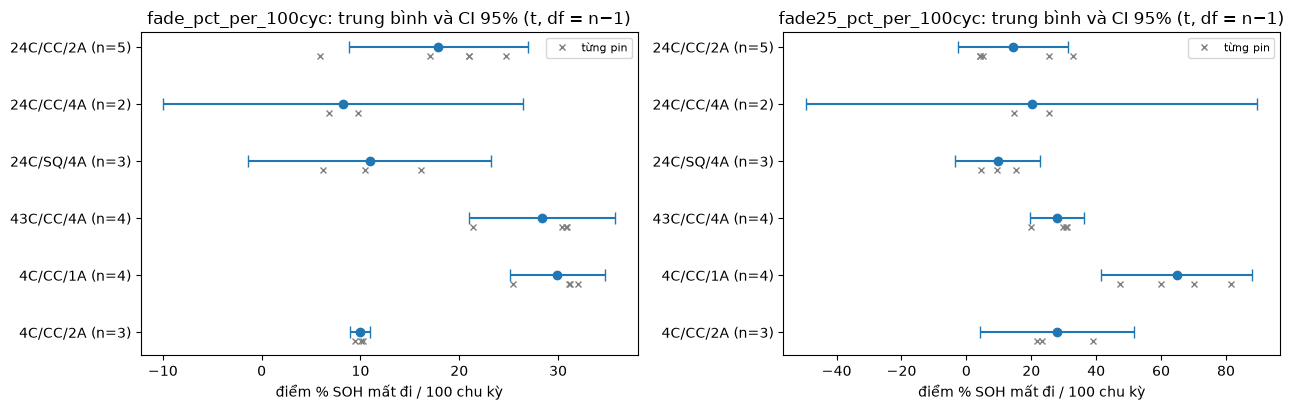

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, (var, col) in zip(axes, Y.items()):
    t = ci_table[ci_table.variable == col].reset_index(drop=True)
    ax.errorbar(t["mean"], range(len(t)), xerr=t.half_width, fmt="o", capsize=4)
    pts = main[[col, "condition"]]
    ax.plot(pts[col], [LEVELS.index(c) + 0.15 for c in pts.condition], "x", color="gray", ms=5, label="từng pin")
    ax.set_yticks(range(len(t)), [f"{c} (n={n})" for c, n in zip(t.condition, t.n)])
    ax.invert_yaxis()
    ax.set_xlabel("điểm % SOH mất đi / 100 chu kỳ")
    ax.set_title(f"{col}: trung bình và CI 95% (t, df = n−1)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "inf_01_ci_by_condition.png", dpi=150)
plt.show()

### 2.2 CI cho một tỉ lệ: tỉ lệ lần xả có dung lượng tăng so với lần xả trước (tr. 16–19)

Tỉ lệ này đo mức độ phổ biến của hiện tượng hồi phục dung lượng (F5). Tính trên các pin tier A và B, bỏ `cap_outlier` và `break_in`, chỉ so hai lần xả liên tiếp **trong cùng một pin**.
Mẫu lớn (np và n(1−p) đều > 5) nên dùng z (tr. 17):

$$\hat{p} \pm z_{0{,}025}\sqrt{\hat{p}(1-\hat{p})/n}$$

**Lưu ý khi diễn giải:** công thức z giả định các lần xả độc lập, nhưng các chu kỳ trong một pin không độc lập (F9). Vì vậy khoảng này **hẹp hơn thực tế**.
Để thấy độ lệch đó, tính thêm một khoảng dựa trên đơn vị là pin: lấy tỉ lệ của từng pin, rồi lập CI t cho trung bình các tỉ lệ đó.

In [5]:
clean = pd.read_csv(DATA / "cycles_clean.csv", usecols=["battery_id", "cycle_valid", "soh", "tier", "cap_outlier", "break_in"])
ab = clean[clean.tier.isin(["A", "B"]) & ~clean.cap_outlier & ~clean.break_in].sort_values(["battery_id", "cycle_valid"])
ab = ab.assign(up=ab.groupby("battery_id").soh.diff() > 0, has_prev=ab.groupby("battery_id").soh.shift().notna())
pairs = ab[ab.has_prev]
n, k = len(pairs), int(pairs.up.sum())
p_hat = k / n
z = stats.norm.ppf(1 - ALPHA / 2)
half = z * np.sqrt(p_hat * (1 - p_hat) / n)
per_cell = pairs.groupby("battery_id").up.mean()
tc = stats.t.ppf(1 - ALPHA / 2, len(per_cell) - 1)
half_cell = tc * per_cell.std(ddof=1) / np.sqrt(len(per_cell))
prop_table = pd.DataFrame([
    {"method": "z, đơn vị = lần xả", "n": n, "k_up": k, "estimate": p_hat, "ci_low": p_hat - half, "ci_high": p_hat + half,
     "check_np_ge_5": min(k, n - k) >= 5},
    {"method": "t, đơn vị = pin (trung bình tỉ lệ của từng pin)", "n": len(per_cell), "k_up": np.nan,
     "estimate": per_cell.mean(), "ci_low": per_cell.mean() - half_cell, "ci_high": per_cell.mean() + half_cell,
     "check_np_ge_5": np.nan}])
print(f"{ab.battery_id.nunique()} pin tier A/B")
prop_table.round(4)

22 pin tier A/B


,method,n,k_up,estimate,ci_low,ci_high,check_np_ge_5
0,"z, đơn vị = lần xả",1966,562.0,0.2859,0.2659,0.3058,True
1,"t, đơn vị = pin (trung bình tỉ lệ của từng pin)",22,NaN,0.2670,0.2229,0.3111,NaN


## 3. So sánh hai nhóm chỉ khác một yếu tố (C2.2–C2.3, Chap 2 tr. 38–53, 64)

| # | So sánh | Nhóm 1 | Nhóm 2 | H0 / Ha |
|---|---|---|---|---|
| T1 | Nhiệt độ ở CC 4 A | 43 °C (G3, n = 4) | 24 °C (B0033, B0034, n = 2) | H0: μ43 ≤ μ24; Ha: μ43 > μ24 (**một phía**) |
| T2 | Nhiệt độ ở CC 2 A | 24 °C (G1 + B0036, n = 5) | 4 °C (G9 trừ B0054, n = 3) | H0: μ24 = μ4; Ha: ≠ |
| T3 | Dòng xả ở 4 °C | CC 1 A (G7, n = 4) | CC 2 A (G9 trừ B0054, n = 3) | H0: μ1A = μ2A; Ha: ≠ |
| T4 | Dạng tải ở 24 °C / 4 A | xung vuông (B0025–27, n = 3) | CC (B0033, B0034, n = 2) | H0: μSQ = μCC; Ha: ≠ |

**Vì sao T1 là một phía:** giả thuyết được nêu **trước khi nhìn số liệu**, dựa trên cơ chế đã biết: nhiệt độ cao đẩy nhanh các phản ứng phụ (lớp SEI dày lên theo quy luật Arrhenius),
nên chỉ quan tâm hướng "43 °C suy giảm nhanh hơn". Ba cặp còn lại không có hướng chắc chắn từ lý thuyết, nên dùng hai phía.

**Quy trình cho mỗi cặp và mỗi biến:**
1. **F-test** tỉ số phương sai (tr. 51), H0: σ₁² = σ₂², hai phía. Chạy thêm **Levene** (tr. 64, `center="median"`) để đối chiếu.
2. Nếu F-test không bác bỏ H0 (p > 0,05) thì dùng **t-test pooled**, df = n₁ + n₂ − 2 (tr. 40). Nếu bác bỏ thì dùng **Welch t-test** (df Welch–Satterthwaite; mở rộng ngoài slide).
3. Báo cáo T, df, giá trị tới hạn, p-value, kết luận, và CI 95% cho chênh lệch μ₁ − μ₂.

**Vì sao dùng t mà không dùng z:** n mỗi nhóm chỉ 2–5 và σ chưa biết, phải ước lượng bằng s. Phân phối t có đuôi dày hơn để bù cho sai số của s (tr. 8, tr. 40).

In [6]:
G1_ONLY = ["B0005", "B0006", "B0007", "B0018"]
PAIRS = {
    "T1": ("43C/CC/4A", "24C/CC/4A", "greater", "Nhiệt độ ở CC 4 A: 43 °C vs 24 °C"),
    "T2": ("24C/CC/2A", "4C/CC/2A", "two-sided", "Nhiệt độ ở CC 2 A: 24 °C vs 4 °C"),
    "T3": ("4C/CC/1A", "4C/CC/2A", "two-sided", "Dòng xả ở 4 °C: 1 A vs 2 A"),
    "T4": ("24C/SQ/4A", "24C/CC/4A", "two-sided", "Dạng tải ở 24 °C/4 A: xung vuông vs CC"),
}


def f_test(a, b):
    """Two-sided F-test of equal variances (Chap 2 tr. 51): F = s1²/s2², df = (n1-1, n2-1)."""
    F = np.var(a, ddof=1) / np.var(b, ddof=1)
    d1, d2 = len(a) - 1, len(b) - 1
    p = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
    return F, d1, d2, min(p, 1.0)


def two_sample(name, a, b, alt, label, col, note=""):
    a, b = np.asarray(a, float), np.asarray(b, float)
    F, d1, d2, pF = f_test(a, b)
    lev = stats.levene(a, b, center="median")
    pooled = pF > ALPHA
    res = stats.ttest_ind(a, b, equal_var=pooled, alternative=alt)
    df = res.df
    tcrit = stats.t.ppf(1 - ALPHA, df) if alt == "greater" else stats.t.ppf(1 - ALPHA / 2, df)
    if pooled:
        sp2 = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
        se = np.sqrt(sp2 * (1 / len(a) + 1 / len(b)))
    else:
        se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    t2 = stats.t.ppf(1 - ALPHA / 2, df)
    diff = a.mean() - b.mean()
    return {"test": name + note, "comparison": label, "variable": col, "n1": len(a), "n2": len(b),
            "mean1": a.mean(), "mean2": b.mean(), "sd1": a.std(ddof=1), "sd2": b.std(ddof=1),
            "F": F, "F_df": f"({d1},{d2})", "p_F": pF, "p_Levene": lev.pvalue,
            "t_test": "pooled" if pooled else "Welch", "Ha": alt, "T": res.statistic, "df": df, "t_crit": tcrit,
            "p": res.pvalue, "reject_H0": res.pvalue < ALPHA,
            "diff": diff, "diff_ci_low": diff - t2 * se, "diff_ci_high": diff + t2 * se}


t_rows = []
for col in Y.values():
    for name, (g1, g2, alt, label) in PAIRS.items():
        a = main.loc[main.condition == g1, col]
        b = main.loc[main.condition == g2, col]
        t_rows.append(two_sample(name, a, b, alt, label, col))
    # T2 bản Go.md: chỉ G1 (n = 4), không gồm B0036
    a = main.loc[main.battery_id.isin(G1_ONLY), col]
    b = main.loc[main.condition == "4C/CC/2A", col]
    t_rows.append(two_sample("T2", a, b, "two-sided", "Nhiệt độ ở CC 2 A: chỉ G1 vs 4 °C", col, note="b (chỉ G1)"))
t_table = pd.DataFrame(t_rows)
t_table.round(4)

,test,comparison,variable,n1,n2,mean1,mean2,sd1,sd2,F,F_df,p_F,p_Levene,t_test,Ha,T,df,t_crit,p,reject_H0,diff,diff_ci_low,diff_ci_high
0,T1,Nhiệt độ ở CC 4 A: 43 °C vs 24 °C,fade_pct_per_100cyc,4,2,28.3730,8.2715,4.6377,2.0284,5.2277,"(3,1)",0.6172,0.7716,pooled,greater,5.6033,4.0000,2.1318,0.0025,True,20.1016,10.1411,30.0620
1,T2,Nhiệt độ ở CC 2 A: 24 °C vs 4 °C,fade_pct_per_100cyc,5,3,17.8967,9.9560,7.2584,0.4119,310.5468,"(4,2)",0.0064,0.2892,Welch,two-sided,2.4397,4.0428,2.7649,0.0706,False,7.9407,-1.0583,16.9398
2,T3,Dòng xả ở 4 °C: 1 A vs 2 A,fade_pct_per_100cyc,4,3,29.9344,9.9560,3.0325,0.4119,54.2068,"(3,2)",0.0363,0.4294,Welch,two-sided,13.0169,3.1465,3.1002,0.0008,True,19.9784,15.2202,24.7366
3,T4,Dạng tải ở 24 °C/4 A: xung vuông vs CC,fade_pct_per_100cyc,3,2,10.9378,8.2715,4.9405,2.0284,5.9327,"(2,1)",0.5576,0.4580,pooled,two-sided,0.6953,3.0000,3.1824,0.5369,False,2.6663,-9.5368,14.8694
4,T2b (chỉ G1),Nhiệt độ ở CC 2 A: chỉ G1 vs 4 °C,fade_pct_per_100cyc,4,3,20.9056,9.9560,3.1446,0.4119,58.2886,"(3,2)",0.0338,0.2642,Welch,two-sided,6.8857,3.1364,3.1056,0.0054,True,10.9497,6.0112,15.8882
5,T1,Nhiệt độ ở CC 4 A: 43 °C vs 24 °C,fade25_pct_per_100cyc,4,2,27.8468,20.1019,5.2637,7.7447,0.4619,"(3,1)",0.4752,0.5260,pooled,greater,1.4952,4.0000,2.1318,0.1046,False,7.7449,-6.6369,22.1266
6,T2,Nhiệt độ ở CC 2 A: 24 °C vs 4 °C,fade25_pct_per_100cyc,5,3,14.4117,27.9244,13.6879,9.5413,2.0580,"(4,2)",0.7054,0.6415,pooled,two-sided,-1.4850,6.0000,2.4469,0.1881,False,-13.5127,-35.7783,8.7530
7,T3,Dòng xả ở 4 °C: 1 A vs 2 A,fade25_pct_per_100cyc,4,3,64.7681,27.9244,14.5533,9.5413,2.3265,"(3,2)",0.6295,0.4093,pooled,two-sided,3.7727,5.0000,2.5706,0.0130,True,36.8438,11.7399,61.9476
8,T4,Dạng tải ở 24 °C/4 A: xung vuông vs CC,fade25_pct_per_100cyc,3,2,9.7227,20.1019,5.2658,7.7447,0.4623,"(2,1)",0.5583,0.4538,pooled,two-sided,-1.8329,3.0000,3.1824,0.1642,False,-10.3792,-28.4004,7.6420
9,T2b (chỉ G1),Nhiệt độ ở CC 2 A: chỉ G1 vs 4 °C,fade25_pct_per_100cyc,4,3,16.9308,27.9244,14.4051,9.5413,2.2794,"(3,2)",0.6389,0.2257,pooled,two-sided,-1.1347,5.0000,2.5706,0.3080,False,-10.9936,-35.8990,13.9118


**Đọc bảng:** `t_test` cho biết đã dùng pooled hay Welch theo kết quả F-test. `diff` là μ₁ − μ₂ (điểm % / 100 chu kỳ), kèm CI 95% hai phía.
Với T1 (một phía), H0 bị bác bỏ khi T > `t_crit` = t(df; 0,05). `T2b` là bản chỉ dùng G1 như Go.md 3.2, để kiểm tra ảnh hưởng của việc gộp B0036.

## 4. One-way ANOVA theo nhóm điều kiện và Tukey HSD (C2.4, Chap 2 tr. 72–89)

Nhân tố là **nhóm điều kiện**, 6 mức, 21 pin. H0: μ₁ = … = μ₆; Ha: có ít nhất một trung bình khác.
Giả định (tr. 75): các quan sát độc lập (đúng, vì mỗi quan sát là một pin), phương sai bằng nhau (Levene), phần dư phân phối chuẩn (QQ-plot và Shapiro-Wilk).
Nếu giả định chuẩn hoặc phương sai bằng nhau bị vi phạm thì chạy thêm **Kruskal-Wallis** (phi tham số, ngoài slide) để đối chiếu.

⚠ Khi diễn giải phải gọi là "nhóm điều kiện", không gọi là "nhiệt độ", vì nhiệt độ bị lẫn với dòng xả và dạng tải.

In [7]:
def anova_table(df, col):
    y = df[col]
    grand = y.mean()
    by = df.groupby("condition")[col]
    ssb = (by.size() * (by.mean() - grand) ** 2).sum()
    ssw = ((y - by.transform("mean")) ** 2).sum()
    k, N = by.ngroups, len(y)
    msb, msw = ssb / (k - 1), ssw / (N - k)
    F = msb / msw
    return pd.DataFrame({"Source": ["Between (điều kiện)", "Within (sai số)", "Total"],
                         "SS": [ssb, ssw, ssb + ssw], "df": [k - 1, N - k, N - 1], "MS": [msb, msw, np.nan],
                         "F": [F, np.nan, np.nan], "F_crit": [stats.f.ppf(1 - ALPHA, k - 1, N - k), np.nan, np.nan],
                         "p": [stats.f.sf(F, k - 1, N - k), np.nan, np.nan]})


anova_out, assumption_rows = {}, []
for col in Y.values():
    samples = [main.loc[main.condition == lv, col].to_numpy() for lv in LEVELS]
    tab = anova_table(main, col)
    fo = stats.f_oneway(*samples)
    assert np.isclose(fo.statistic, tab.F[0]) and np.isclose(fo.pvalue, tab.p[0])   # bảng tự tính khớp scipy
    resid = main[col] - main.groupby("condition")[col].transform("mean")
    lev = stats.levene(*samples, center="median")
    sh = stats.shapiro(resid)
    kw = stats.kruskal(*samples)
    anova_out[col] = (tab, resid)
    assumption_rows.append({"variable": col, "F": fo.statistic, "p_ANOVA": fo.pvalue, "p_Levene": lev.pvalue,
                            "p_Shapiro_resid": sh.pvalue, "H_Kruskal": kw.statistic, "p_Kruskal": kw.pvalue})
    print(f"\nBảng ANOVA: {col}")
    print(tab.round(4).to_string(index=False))
assumptions = pd.DataFrame(assumption_rows)
assumptions.round(4)


Bảng ANOVA: fade_pct_per_100cyc
             Source        SS  df       MS       F  F_crit      p
Between (điều kiện) 1505.9149   5 301.1830 12.6858  2.9013 0.0001
    Within (sai số)  356.1248  15  23.7417     NaN     NaN    NaN
              Total 1862.0398  20      NaN     NaN     NaN    NaN

Bảng ANOVA: fade25_pct_per_100cyc
             Source        SS  df        MS       F  F_crit      p
Between (điều kiện) 7455.0437   5 1491.0087 12.6682  2.9013 0.0001
    Within (sai số) 1765.4614  15  117.6974     NaN     NaN    NaN
              Total 9220.5052  20       NaN     NaN     NaN    NaN


,variable,F,p_ANOVA,p_Levene,p_Shapiro_resid,H_Kruskal,p_Kruskal
0,fade_pct_per_100cyc,12.6858,0.0001,0.7626,0.0415,15.5511,0.0082
1,fade25_pct_per_100cyc,12.6682,0.0001,0.6862,0.6124,13.1221,0.0223


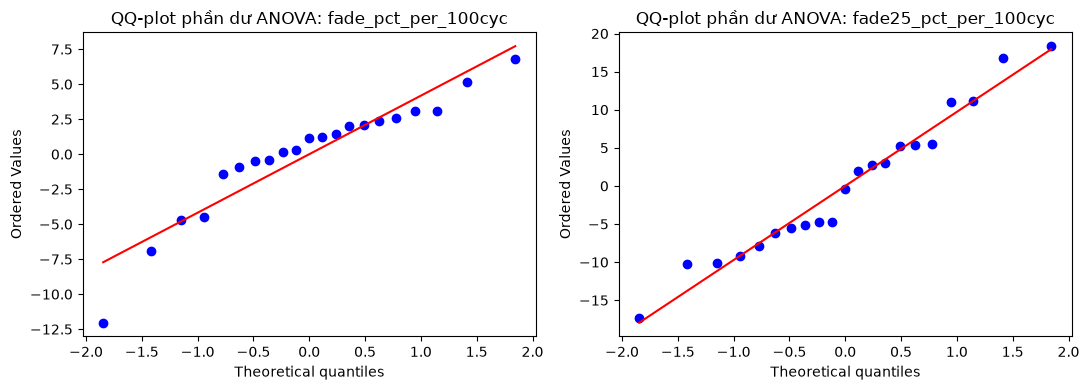

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, Y.values()):
    stats.probplot(anova_out[col][1], dist="norm", plot=ax)
    ax.set_title(f"QQ-plot phần dư ANOVA: {col}")
fig.tight_layout()
fig.savefig(FIG / "inf_02_anova_qq.png", dpi=150)
plt.show()

In [9]:
tukey_rows = []
for col in Y.values():
    tk = pairwise_tukeyhsd(main[col], main.condition, alpha=ALPHA)
    t = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    t.insert(0, "variable", col)
    tukey_rows.append(t)
tukey = pd.concat(tukey_rows, ignore_index=True)
print("Tukey HSD (meandiff = group2 − group1). Chỉ diễn giải khi ANOVA của biến đó có p < 0,05.")
tukey[tukey.reject]

Tukey HSD (meandiff = group2 − group1). Chỉ diễn giải khi ANOVA của biến đó có p < 0,05.


,variable,group1,group2,meandiff,p-adj,lower,upper,reject
3,fade_pct_per_100cyc,24C/CC/2A,4C/CC/1A,12.0376,0.0221,1.4181,22.6572,True
6,fade_pct_per_100cyc,24C/CC/4A,43C/CC/4A,20.1016,0.0028,6.3917,33.8114,True
7,fade_pct_per_100cyc,24C/CC/4A,4C/CC/1A,21.6629,0.0014,7.9531,35.3727,True
9,fade_pct_per_100cyc,24C/SQ/4A,43C/CC/4A,17.4353,0.0033,5.3443,29.5262,True
10,fade_pct_per_100cyc,24C/SQ/4A,4C/CC/1A,18.9966,0.0015,6.9057,31.0875,True
13,fade_pct_per_100cyc,43C/CC/4A,4C/CC/2A,-18.4171,0.0020,-30.5080,-6.3262,True
14,fade_pct_per_100cyc,4C/CC/1A,4C/CC/2A,-19.9784,0.0009,-32.0693,-7.8875,True
18,fade25_pct_per_100cyc,24C/CC/2A,4C/CC/1A,50.3564,0.0001,26.7116,74.0012,True
22,fade25_pct_per_100cyc,24C/CC/4A,4C/CC/1A,44.6662,0.0029,14.1410,75.1915,True
25,fade25_pct_per_100cyc,24C/SQ/4A,4C/CC/1A,55.0454,0.0001,28.1247,81.9662,True


In [10]:
tukey

,variable,group1,group2,meandiff,p-adj,lower,upper,reject
0,fade_pct_per_100cyc,24C/CC/2A,24C/CC/4A,-9.6252,0.2305,-22.8702,3.6197,False
1,fade_pct_per_100cyc,24C/CC/2A,24C/SQ/4A,-6.9589,0.4091,-18.5201,4.6022,False
2,fade_pct_per_100cyc,24C/CC/2A,43C/CC/4A,10.4763,0.0542,-0.1432,21.0959,False
3,fade_pct_per_100cyc,24C/CC/2A,4C/CC/1A,12.0376,0.0221,1.4181,22.6572,True
4,fade_pct_per_100cyc,24C/CC/2A,4C/CC/2A,-7.9407,0.2800,-19.5019,3.6204,False
5,fade_pct_per_100cyc,24C/CC/4A,24C/SQ/4A,2.6663,0.9895,-11.7851,17.1177,False
6,fade_pct_per_100cyc,24C/CC/4A,43C/CC/4A,20.1016,0.0028,6.3917,33.8114,True
7,fade_pct_per_100cyc,24C/CC/4A,4C/CC/1A,21.6629,0.0014,7.9531,35.3727,True
8,fade_pct_per_100cyc,24C/CC/4A,4C/CC/2A,1.6845,0.9988,-12.7669,16.1359,False
9,fade_pct_per_100cyc,24C/SQ/4A,43C/CC/4A,17.4353,0.0033,5.3443,29.5262,True


## 5. Vì sao không làm được two-way ANOVA (C2.5, Chap 2 tr. 90)

Two-way ANOVA với nhân tố nhiệt độ × dòng xả cần **có quan sát ở mọi ô** (slide dùng thiết kế cân bằng, cùng cỡ mẫu ở mọi ô) và ít nhất 2 quan sát mỗi ô để ước lượng tương tác.
Bảng số pin theo ô dưới đây (chỉ tính CC, mẫu chính) cho thấy điều kiện đó không thỏa.

In [11]:
cc = main[main.condition.str.contains("/CC/")]
cells = pd.crosstab(cc.ambient_C, cc.I_level_A).reindex(index=[4.0, 24.0, 43.0], columns=[1.0, 2.0, 4.0], fill_value=0)
cells.index = [f"{t:.0f} °C" for t in cells.index]
cells.columns = [f"{i:.0f} A" for i in cells.columns]
print(f"Số ô trống: {(cells == 0).sum().sum()} / {cells.size}")
cells

Số ô trống: 4 / 9


,1 A,2 A,4 A
4 °C,4,3,0
24 °C,0,5,2
43 °C,0,0,4


**Giải thích (đưa vào Report §4):** trong 9 ô nhiệt độ × dòng xả có 4 ô trống: không có pin nào chạy 1 A ở 24 °C hay 43 °C, 2 A ở 43 °C, hay 4 A ở 4 °C.
Các ô có dữ liệu cũng không cân bằng (2 đến 5 pin). Thiết kế thí nghiệm của NASA không phải dạng giai thừa đầy đủ (full factorial): mỗi nhiệt độ chỉ đi với một vài mức dòng.
Vì vậy:
- không ước lượng được hiệu ứng tương tác nhiệt độ × dòng, vì tương tác cần mọi tổ hợp mức;
- hiệu ứng chính của nhiệt độ bị lẫn với dòng xả (43 °C chỉ có 4 A, 4 °C chỉ có 1 A và 2 A).

Do đó nhóm dùng **one-way ANOVA theo nhóm điều kiện** (mục 4) và các **cặp chỉ khác một yếu tố** (T1–T4, mục 3) để tách từng yếu tố.

## 6. Chi-square: nhóm nhiệt độ × "SOH < 0,9 trong W chu kỳ đầu" (C2.6, Chap 2 tr. 56–63)

Bảng chéo ở **mức pin**. Biến kết quả: pin có ít nhất một lần xả với SOH < 0,9 trong `cycle_valid` ≤ W hay không (bỏ `cap_outlier` và `break_in`).
H0: nhóm nhiệt độ và kết quả độc lập. Bảng tần số kỳ vọng E_ij = (tổng hàng × tổng cột) / n như tr. 59–60.

**Chọn W.** Go.md 3.5 chọn W = 40 với lý do "đây là số chu kỳ ngắn nhất của G3, nên mọi pin đều được quan sát đủ". Kiểm tra dữ liệu cho thấy lý do này **không khớp**:
G3 (B0029–B0032) chỉ có 39 lần xả hợp lệ (`cycle_valid` 1–39), và các pin xung vuông G2 (B0025–B0027) chỉ tới `cycle_valid` 28. Với W = 40, các pin này được quan sát
ít hơn các pin khác nên dễ bị xếp "không" chỉ vì chưa đủ chu kỳ. Vì vậy:
- **Bản chính: W = 25**, cửa sổ mà mọi pin đều có (cùng cửa sổ với `fade25_pct_per_100cyc`), 21 pin.
- **Bản kiểm tra: W = 39**, gần nhất với ý định của Go.md, chỉ trên các pin có đủ 39 chu kỳ (bỏ G2).

Khi có ô E_ij < 5 thì xấp xỉ χ² không đáng tin (tr. 61). Fisher exact chỉ áp dụng trực tiếp cho bảng 2 × 2, nên dùng thêm **kiểm định hoán vị** (permutation test, ngoài slide):
giữ nguyên tổng hàng và tổng cột, xáo trộn nhãn nhiệt độ giữa các pin 20.000 lần, p = tỉ lệ lần xáo trộn cho χ² ≥ χ² quan sát. Seed = 42 để tái lập được.

In [12]:
REPS = 20000
last_valid = clean[~clean.cap_outlier & ~clean.break_in].groupby("battery_id").cycle_valid.max()


def chi2_stat(l, o):
    tab = pd.crosstab(l, o).to_numpy()
    return stats.chi2_contingency(tab, correction=False)[0] if tab.shape[1] == 2 else 0.0


def chi_square(window, cells):
    early = clean[clean.battery_id.isin(cells) & ~clean.cap_outlier & ~clean.break_in & (clean.cycle_valid <= window)]
    reach = early.groupby("battery_id").cycle_valid.max()
    below = early.groupby("battery_id").soh.min().lt(0.9).rename("below")
    df = main.set_index("battery_id").loc[list(cells), ["ambient_C"]].join(below)
    obs = pd.crosstab(df.ambient_C, df.below).reindex(columns=[False, True], fill_value=0)
    obs.index = [f"{t:.0f} °C" for t in obs.index]
    obs.columns = ["không", "có (SOH < 0,9)"]
    chi2, p_chi, dof, exp = stats.chi2_contingency(obs.to_numpy(), correction=False)
    exp = pd.DataFrame(exp, index=obs.index, columns=obs.columns)
    rng = np.random.default_rng(42)
    lab, out = df.ambient_C.to_numpy(), df.below.to_numpy()
    perm = np.array([chi2_stat(rng.permutation(lab), out) for _ in range(REPS)])
    p_perm = (np.sum(perm >= chi2 - 1e-12) + 1) / (REPS + 1)
    print(f"=== W = {window}, {len(df)} pin; cycle_valid lớn nhất trong cửa sổ, nhỏ nhất qua các pin = {reach.min()}")
    print("Bảng quan sát O_ij"); print(obs.to_string())
    print("Bảng kỳ vọng E_ij"); print(exp.round(2).to_string())
    print(f"χ² = {chi2:.4f}, df = {dof}, χ²_crit = {stats.chi2.ppf(1 - ALPHA, dof):.4f}, p (χ²) = {p_chi:.4f}, "
          f"p (permutation) = {p_perm:.4f}; số ô E_ij < 5: {int((exp < 5).sum().sum())}/{exp.size}\n")
    return {"window": window, "n_cells": len(df), "chi2": chi2, "df": dof, "p_chi2": p_chi, "p_perm": p_perm,
            "n_cells_E_lt_5": int((exp < 5).sum().sum())}


chi_main = chi_square(25, main.battery_id)
cells39 = [b for b in main.battery_id if last_valid[b] >= 39]
print("Bỏ khỏi bản W = 39 (chưa tới 39 chu kỳ):", sorted(set(main.battery_id) - set(cells39)))
chi_39 = chi_square(39, cells39)
chi_table = pd.DataFrame([chi_main, chi_39])
chi_table.round(4)

=== W = 25, 21 pin; cycle_valid lớn nhất trong cửa sổ, nhỏ nhất qua các pin = 25
Bảng quan sát O_ij
       không  có (SOH < 0,9)
4 °C       1               6
24 °C      9               1
43 °C      4               0
Bảng kỳ vọng E_ij
       không  có (SOH < 0,9)
4 °C    4.67            2.33
24 °C   6.67            3.33
43 °C   2.67            1.33
χ² = 13.0929, df = 2, χ²_crit = 5.9915, p (χ²) = 0.0014, p (permutation) = 0.0014; số ô E_ij < 5: 5/6

Bỏ khỏi bản W = 39 (chưa tới 39 chu kỳ): ['B0025', 'B0026', 'B0027']


=== W = 39, 18 pin; cycle_valid lớn nhất trong cửa sổ, nhỏ nhất qua các pin = 39
Bảng quan sát O_ij
       không  có (SOH < 0,9)
4 °C       1               6
24 °C      4               3
43 °C      1               3
Bảng kỳ vọng E_ij
       không  có (SOH < 0,9)
4 °C    2.33            4.67
24 °C   2.33            4.67
43 °C   1.33            2.67
χ² = 3.0536, df = 2, χ²_crit = 5.9915, p (χ²) = 0.2172, p (permutation) = 0.3194; số ô E_ij < 5: 6/6



,window,n_cells,chi2,df,p_chi2,p_perm,n_cells_E_lt_5
0,25,21,13.0929,2,0.0014,0.0014,5
1,39,18,3.0536,2,0.2172,0.3194,6


## 7. Tương quan giữa tốc độ suy giảm và nhiệt độ của chính cell (C2.7)

Kết quả T3 gợi ý: ở 4 °C, dòng 2 A làm cell tự nóng lên hơn, nên có thể **nhiệt độ của cell** (`T_max_med`, trung vị nhiệt độ cao nhất mỗi lần xả)
quan trọng hơn nhiệt độ môi trường. Tính Pearson r kèm kiểm định t (H0: ρ = 0, df = n − 2) và Spearman ρ (phi tham số, để đối chiếu vì quan hệ có thể không tuyến tính).

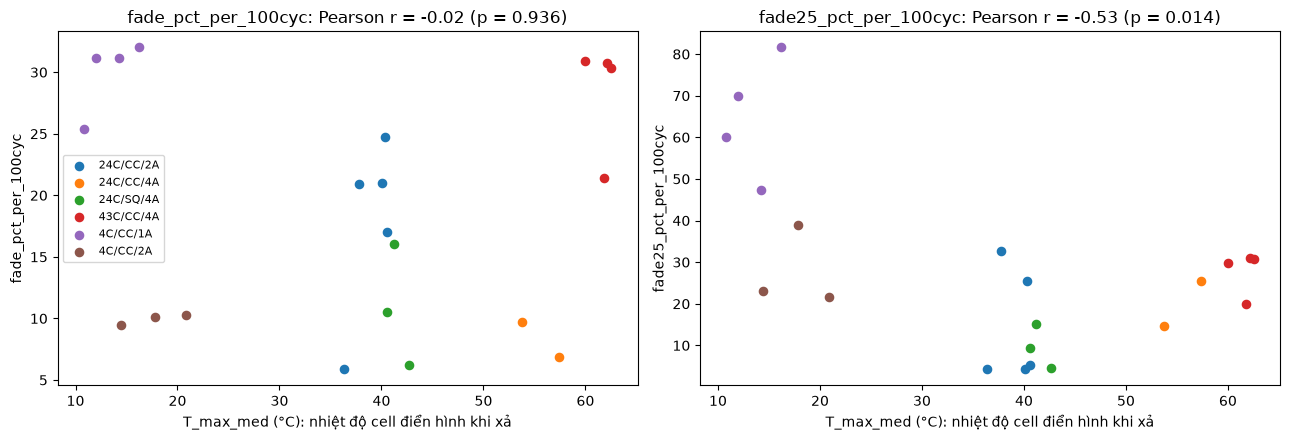

,variable,n,pearson_r,p_pearson,spearman_rho,p_spearman
0,fade_pct_per_100cyc,21,-0.0185,0.9365,-0.1065,0.6459
1,fade25_pct_per_100cyc,21,-0.5293,0.0136,-0.3792,0.0900


In [13]:
corr_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, Y.values()):
    pr = stats.pearsonr(main.T_max_med, main[col])
    sr = stats.spearmanr(main.T_max_med, main[col])
    corr_rows.append({"variable": col, "n": len(main), "pearson_r": pr.statistic, "p_pearson": pr.pvalue,
                      "spearman_rho": sr.statistic, "p_spearman": sr.pvalue})
    for lv in LEVELS:
        d = main[main.condition == lv]
        ax.scatter(d.T_max_med, d[col], label=lv, s=35)
    ax.set_xlabel("T_max_med (°C): nhiệt độ cell điển hình khi xả")
    ax.set_ylabel(col)
    ax.set_title(f"{col}: Pearson r = {pr.statistic:.2f} (p = {pr.pvalue:.3f})")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "inf_03_fade_vs_cell_temp.png", dpi=150)
plt.show()
corr_table = pd.DataFrame(corr_rows)
corr_table.round(4)

Hình cho thấy quan hệ **không đơn điệu**: tốc độ suy giảm cao ở cả hai đầu (cell lạnh nhất ở 4 °C/1 A và cell nóng nhất ở 43 °C) và thấp hơn ở giữa.
Vì vậy hệ số tương quan tuyến tính trên toàn mẫu không đo đúng quan hệ này. So sánh riêng trong nhóm 4 °C (cùng nhiệt độ môi trường, khác nhiệt độ cell):

In [14]:
cold = main[main.ambient_C == 4]
cold_rows = []
for col in Y.values():
    pr = stats.pearsonr(cold.T_max_med, cold[col])
    sr = stats.spearmanr(cold.T_max_med, cold[col])
    cold_rows.append({"subset": "4 °C (G7 + G9)", "variable": col, "n": len(cold), "pearson_r": pr.statistic,
                      "p_pearson": pr.pvalue, "spearman_rho": sr.statistic, "p_spearman": sr.pvalue})
pd.DataFrame(cold_rows).round(4)

,subset,variable,n,pearson_r,p_pearson,spearman_rho,p_spearman
0,4 °C (G7 + G9),fade_pct_per_100cyc,7,-0.5861,0.1667,-0.3214,0.4821
1,4 °C (G7 + G9),fade25_pct_per_100cyc,7,-0.5177,0.2340,-0.5357,0.2152


## 8. Bảng tổng hợp (C2.8)

Bảng dưới gom mọi kiểm định của notebook, được tạo tự động từ các kết quả ở trên và lưu vào `reports/tables/inference_summary.csv`.
Cột "Ý nghĩa thực tế" được viết ở mục 9 sau khi đọc bảng.

In [15]:
summary = []
for r in t_table.itertuples():
    summary.append({"test": r.test, "variable": r.variable, "H0": f"μ({r.comparison.split(': ')[1].split(' vs ')[0]}) "
                    f"{'≤' if r.Ha == 'greater' else '='} μ({r.comparison.split(' vs ')[1]})",
                    "method": f"{r.t_test} t-test, {'một phía' if r.Ha == 'greater' else 'hai phía'}",
                    "statistic": f"T = {r.T:.3f}", "df": round(r.df, 2), "p": r.p,
                    "decision": "bác bỏ H0" if r.reject_H0 else "không bác bỏ H0"})
for a in assumptions.itertuples():
    tab = anova_out[a.variable][0]
    summary.append({"test": "ANOVA", "variable": a.variable, "H0": "6 nhóm điều kiện có cùng trung bình",
                    "method": "one-way ANOVA", "statistic": f"F = {a.F:.3f}", "df": f"({int(tab.df[0])},{int(tab.df[1])})",
                    "p": a.p_ANOVA, "decision": "bác bỏ H0" if a.p_ANOVA < ALPHA else "không bác bỏ H0"})
    summary.append({"test": "Kruskal-Wallis", "variable": a.variable, "H0": "6 nhóm điều kiện có cùng phân phối",
                    "method": "phi tham số", "statistic": f"H = {a.H_Kruskal:.3f}", "df": int(tab.df[0]),
                    "p": a.p_Kruskal, "decision": "bác bỏ H0" if a.p_Kruskal < ALPHA else "không bác bỏ H0"})
for c in chi_table.itertuples():
    summary.append({"test": f"Chi-square (W = {c.window})", "variable": f"SOH < 0,9 trong {c.window} chu kỳ ({c.n_cells} pin)",
                    "H0": "nhóm nhiệt độ độc lập với kết quả", "method": "χ² + permutation (vì E_ij < 5)",
                    "statistic": f"χ² = {c.chi2:.3f}", "df": c.df, "p": c.p_perm,
                    "decision": "bác bỏ H0" if c.p_perm < ALPHA else "không bác bỏ H0"})
for c in corr_table.itertuples():
    summary.append({"test": "Pearson", "variable": c.variable, "H0": "ρ(T_max_med, fade) = 0 (21 pin)",
                    "method": "t-test của r", "statistic": f"r = {c.pearson_r:.3f}", "df": c.n - 2, "p": c.p_pearson,
                    "decision": "bác bỏ H0" if c.p_pearson < ALPHA else "không bác bỏ H0"})
summary = pd.DataFrame(summary)
summary.to_csv(TAB / "inference_summary.csv", index=False)
t_table.to_csv(TAB / "inference_ttests.csv", index=False)
ci_table.to_csv(TAB / "inference_ci.csv", index=False)
summary.assign(p=summary.p.round(4))

,test,variable,H0,method,statistic,df,p,decision
0,T1,fade_pct_per_100cyc,μ(43 °C) ≤ μ(24 °C),"pooled t-test, một phía",T = 5.603,4.0,0.0025,bác bỏ H0
1,T2,fade_pct_per_100cyc,μ(24 °C) = μ(4 °C),"Welch t-test, hai phía",T = 2.440,4.04,0.0706,không bác bỏ H0
2,T3,fade_pct_per_100cyc,μ(1 A) = μ(2 A),"Welch t-test, hai phía",T = 13.017,3.15,0.0008,bác bỏ H0
3,T4,fade_pct_per_100cyc,μ(xung vuông) = μ(CC),"pooled t-test, hai phía",T = 0.695,3.0,0.5369,không bác bỏ H0
4,T2b (chỉ G1),fade_pct_per_100cyc,μ(chỉ G1) = μ(4 °C),"Welch t-test, hai phía",T = 6.886,3.14,0.0054,bác bỏ H0
5,T1,fade25_pct_per_100cyc,μ(43 °C) ≤ μ(24 °C),"pooled t-test, một phía",T = 1.495,4.0,0.1046,không bác bỏ H0
6,T2,fade25_pct_per_100cyc,μ(24 °C) = μ(4 °C),"pooled t-test, hai phía",T = -1.485,6.0,0.1881,không bác bỏ H0
7,T3,fade25_pct_per_100cyc,μ(1 A) = μ(2 A),"pooled t-test, hai phía",T = 3.773,5.0,0.0130,bác bỏ H0
8,T4,fade25_pct_per_100cyc,μ(xung vuông) = μ(CC),"pooled t-test, hai phía",T = -1.833,3.0,0.1642,không bác bỏ H0
9,T2b (chỉ G1),fade25_pct_per_100cyc,μ(chỉ G1) = μ(4 °C),"pooled t-test, hai phía",T = -1.135,5.0,0.3080,không bác bỏ H0


## 9. Kết luận và ý nghĩa thực tế (C2.8, để viết Report §5.2)

Các con số dưới đây đọc từ các bảng ở mục 2–8. "fade" = `fade_pct_per_100cyc` (cả chuỗi), "fade25" = `fade25_pct_per_100cyc` (25 chu kỳ đầu).

| Kiểm định | Kết quả | Có vững qua hai biến không? | Ý nghĩa thực tế |
|---|---|---|---|
| CI theo nhóm (2.1) | Khoảng rất rộng khi n nhỏ. Ví dụ 24 °C/CC 4 A (n = 2): fade 8,3, CI từ −10,0 đến 26,5 | – | 21 pin là quá ít để định lượng chính xác tốc độ suy giảm của từng điều kiện. Mọi con số dùng cho bảo hành cần thêm dữ liệu. |
| CI tỉ lệ hồi phục (2.2) | 28,6% số lần xả có dung lượng tăng so với lần trước (z: 26,6–30,6%). Tính theo pin: 26,7% (t: 22,3–31,1%) | – | Dung lượng đo được dao động đáng kể giữa các lần xả. Không nên kết luận pin "tốt lên" từ một lần đo; cần làm trơn hoặc nhìn xu hướng nhiều chu kỳ. |
| T1: 43 °C > 24 °C ở 4 A | fade: bác bỏ H0 (p = 0,0025). fade25: không bác bỏ (p = 0,105), dù cùng hướng (27,8 so với 20,1) | **Không** | Kết quả cả chuỗi bị lệch, vì G3 chỉ chạy 39 chu kỳ còn B0033/B0034 chạy tới khoảng 190 chu kỳ, có đoạn chững lại kéo độ dốc xuống. Trên cửa sổ công bằng (fade25), hướng đúng như kỳ vọng nhưng chưa đủ bằng chứng với 4 và 2 pin. Quản lý nhiệt vẫn là khuyến nghị hợp lý, nhưng dựa vào cơ chế đã biết nhiều hơn là vào dữ liệu này. |
| T2: 24 °C vs 4 °C ở 2 A | Không bác bỏ ở cả hai biến (p = 0,071 và 0,188). Bản chỉ G1 (T2b): fade bác bỏ (p = 0,0054), fade25 không | **Không** | Kết luận phụ thuộc việc có gộp B0036 (fade 5,9, thấp hơn hẳn G1) hay không. Không đủ cơ sở nói 24 °C hay 4 °C hại hơn ở 2 A. |
| T3: 1 A vs 2 A ở 4 °C | Bác bỏ ở cả hai biến: fade chênh 20,0 (CI 15,2–24,7; p = 0,0008), fade25 chênh 36,8 (CI 11,7–61,9; p = 0,013) | **Có** | Kết quả vững nhất: ở 4 °C, xả dòng nhỏ 1 A làm pin suy giảm **nhanh hơn** xả 2 A. Ngược trực giác; giải thích khả dĩ là dòng 2 A làm cell tự nóng lên (mục 7). Với đội xe ở vùng lạnh: nên làm ấm pin trước khi chạy tải nhẹ, và điều khoản bảo hành cần tính tới khí hậu lạnh. |
| T4: xung vuông vs CC ở 24 °C/4 A | Không bác bỏ ở cả hai biến (p = 0,537 và 0,164) | Có (cùng không khác) | Không có bằng chứng dạng tải xung 0,05 Hz làm pin già nhanh hơn tải liên tục cùng biên độ. Chưa cần tách điều khoản bảo hành theo dạng tải. |
| ANOVA 6 nhóm điều kiện | Bác bỏ ở cả hai biến (F = 12,69 và 12,67; p = 0,0001). Levene không bác bỏ. Shapiro bác bỏ ở fade (p = 0,042), nhưng Kruskal-Wallis vẫn bác bỏ (p = 0,008 và 0,022) | **Có** | Điều kiện vận hành ảnh hưởng thật tới tốc độ suy giảm. Tukey: 4 °C/1 A khác đa số nhóm ở cả hai biến. Ở fade, 43 °C/4 A còn khác 24 °C/CC 4 A, 24 °C/xung vuông và 4 °C/2 A; ở fade25 thì 43 °C/4 A chỉ khác 4 °C/1 A. |
| Two-way ANOVA | Không làm được: 4/9 ô trống | – | Không tách được tương tác nhiệt độ × dòng. Thiết kế thử nghiệm tiếp theo nên là giai thừa đầy đủ. |
| Chi-square | W = 25: bác bỏ (χ² = 13,09; p hoán vị = 0,0014). W = 39: không bác bỏ (p hoán vị = 0,319) | **Không** | Pin ở 4 °C xuống dưới 0,9 sớm hơn hẳn trong 25 chu kỳ đầu, nhưng tới khoảng 39 chu kỳ thì pin ở cả ba mức nhiệt độ đều có nhiều pin dưới 0,9. Lạnh làm mất dung lượng **sớm**, chứ chưa chắc làm mất nhiều hơn về lâu dài. |
| Tương quan với nhiệt độ cell | fade: r = −0,02 (p = 0,94). fade25: r = −0,53 (p = 0,014). Trong riêng nhóm 4 °C (n = 7): r âm nhưng không có ý nghĩa | **Không** | Quan hệ không tuyến tính (hai đầu lạnh và nóng đều xấu). Giả thuyết "nhiệt độ của cell quan trọng hơn nhiệt độ môi trường" mới chỉ được ủng hộ về hướng; cần thêm pin để kiểm định. |

**Nhận xét chung:**
- Ở các cặp T2 và T3, F-test bác bỏ phương sai bằng nhau còn Levene thì không. Lý do là nhóm 4 °C/2 A có độ lệch chuẩn rất nhỏ (0,41). Theo quy trình đã định trước, quyết định dựa vào F-test (slide), nên các cặp này dùng Welch.
- Với n = 2 đến 5 pin mỗi nhóm, power của các kiểm định rất thấp. "Không bác bỏ H0" ở đây phải đọc là "chưa đủ bằng chứng", **không** phải "không có khác biệt".
- Hai cách đo tốc độ suy giảm cho kết luận khác nhau ở T1, T2, chi-square và tương quan. Báo cáo phải trình bày cả hai, như Introduction_of_dataset.md mục 8 đã lưu ý.

**Đầu ra:**
- Bảng: `reports/tables/inference_summary.csv` (bảng tổng hợp), `inference_ttests.csv` (chi tiết T1–T4), `inference_ci.csv` (CI theo nhóm).
- Hình: `reports/figures/inf_01_ci_by_condition.png`, `inf_02_anova_qq.png`, `inf_03_fade_vs_cell_temp.png`.